# Imports

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Question 1

In [2]:
# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

classes = (
    'plane', 'car', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
)


Epoch 1/10, Loss: 0.9769931159615517
Epoch 2/10, Loss: 0.9498868247866631
Epoch 3/10, Loss: 0.9361308252811432
Epoch 4/10, Loss: 0.9275737428665161
Epoch 5/10, Loss: 0.921630845963955
Epoch 6/10, Loss: 0.9172225728631019
Epoch 7/10, Loss: 0.9138054001927376
Epoch 8/10, Loss: 0.9110757853984833
Epoch 9/10, Loss: 0.9088452054858208
Epoch 10/10, Loss: 0.9069916223883628


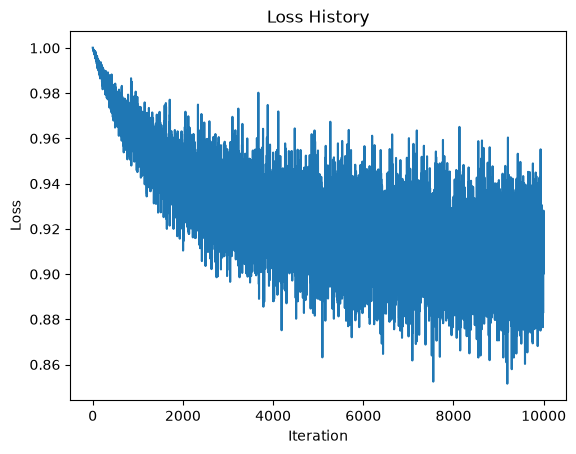

Training accuracy: 30.98%
Test accuracy: 31.05%


In [3]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w = torch.randn(Din, K) * std
b = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # Loss calculation (MSE with regularization)
        loss = (
            (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2)
            + reg * torch.sum(w ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)

        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        # Parameter update
        w -= lr * dw
        b -= lr * db

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_train_pred = x_train.mm(w) + b
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_test_pred = x_test.mm(w) + b
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


Epoch 1/10, Loss: 2.243076278924942
Epoch 2/10, Loss: 2.122730359792709
Epoch 3/10, Loss: 2.074737793684006
Epoch 4/10, Loss: 2.0429054455757143
Epoch 5/10, Loss: 2.0195114542245864
Epoch 6/10, Loss: 2.001456614255905
Epoch 7/10, Loss: 1.9870759375095368
Epoch 8/10, Loss: 1.975373396396637
Epoch 9/10, Loss: 1.9656636222600936
Epoch 10/10, Loss: 1.9575251314640045


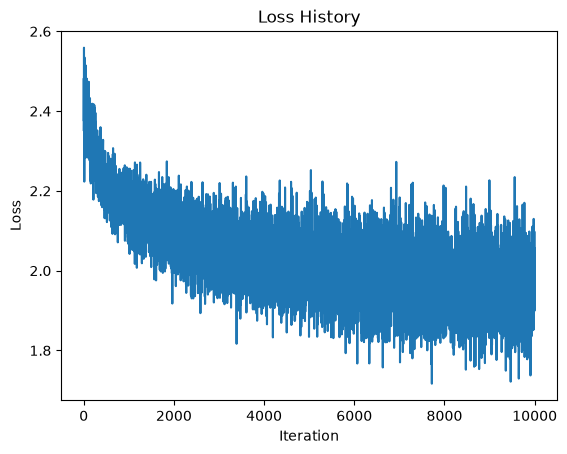

Training accuracy: 33.04%
Test accuracy: 33.15%


In [4]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Hidden layer size
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-5

# Initialize weights and biases
w1 = torch.randn(Din, H) * (1 / Din**0.5)
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * (1 / H**0.5)
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10
lr = 1e-3
lr_decay = 0.9
reg = 0
loss_history = []

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Convert labels to one-hot encoding
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_train.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_pred = hidden1.mm(w2) + b2

        # Loss calculation (cross-entropy with regularization)
        loss = (
            nn.functional.cross_entropy(y_pred, labels)
            + reg * torch.sum(w1 ** 2)
            + reg * torch.sum(w2 ** 2)
        )

        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = torch.softmax(y_pred, dim=1)
        dy_pred[torch.arange(Ntr), labels] -= 1
        dy_pred /= Ntr

        dw2 = hidden1.t().mm(dy_pred) + 2 * reg * w2
        db2 = dy_pred.sum(dim=0)

        dhidden = dy_pred.mm(w2.t()) * hidden1 * (1 - hidden1)

        dw1 = x_train.t().mm(dhidden) + 2 * reg * w1
        db1 = dhidden.sum(dim=0)

        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    # Print loss for every epoch
    if t % 1 == 0:
        print(
            f"Epoch {t + 1}/{iterations}, "
            f"Loss: {running_loss / len(trainloader)}"
        )

    # Learning rate decay
    lr *= lr_decay

# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_train.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_train_pred = hidden1.mm(w2) + b2
        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        y_test_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        hidden1 = x_test.mm(w1) + b1
        hidden1 = torch.sigmoid(hidden1)
        y_test_pred = hidden1.mm(w2) + b2
        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")


With the same parameters the model with the hidden layer performs much worse. This is due to much slower learning rate implemented. Increasing the learning rate gave the model same performance as the original model. 